In [133]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [134]:
data_path = r"runs\28-10-2026\champion-episodes.csv"

pd.set_option('display.max_columns', None)
df = pd.read_csv(data_path)
print(df.columns)
df.head()


Index(['generation', 'role', 'track_name', 'track_hash', 'track_seed', 'split',
       'difficulty', 'features', 'completed', 'termination', 'error',
       'elapsed_s', 'completion_time_s', 'time_limit_s', 'progress',
       'progress_m', 'route_length_m', 'lateral_rmse_m', 'sensor_index_rmse',
       'average_forward_speed_m_s', 'line_loss_events', 'line_loss_seconds',
       'unplanned_line_loss_events', 'mean_action_L', 'mean_action_R',
       'motor_asymmetry', 'control_steps', 'physics_steps', 'legacy_return',
       'score'],
      dtype='object')


,generation,role,track_name,track_hash,track_seed,split,difficulty,features,completed,termination,error,elapsed_s,completion_time_s,time_limit_s,progress,progress_m,route_length_m,lateral_rmse_m,sensor_index_rmse,average_forward_speed_m_s,line_loss_events,line_loss_seconds,unplanned_line_loss_events,mean_action_L,mean_action_R,motor_asymmetry,control_steps,physics_steps,legacy_return,score
0,0,training_champion,beginner-14041274932902259002,6e922dc9e2ab4c0ed6d56d3aac2fd900fd8cc70f162c61...,14041274932902259002,training,beginner,gentle_curve;straight,True,completed,NaN,6.283333,6.283333,60,1.0,1.624601,1.624601,0.008205,0.376709,0.254726,0,0.0,0,0.994446,0.725024,0.279513,377,3770,191502.798988,1.999528
1,0,training_champion,beginner-17965099703021808193,1c9dbf0c80008c4d39f7e1b0e08f2ae836c7fca7910a87...,17965099703021808193,training,beginner,gentle_curve;straight,True,completed,NaN,7.566667,7.566667,60,1.0,1.907756,1.907756,0.005895,0.734982,0.252373,0,0.0,0,0.733712,0.969485,0.238228,454,4540,224446.931260,1.997389
2,0,training_champion,beginner-5483539780884278178,b776faaa7bd3635b42af75f6299bfaf8cc3f7f78537f77...,5483539780884278178,training,beginner,gentle_curve;straight,True,completed,NaN,7.266667,7.266667,60,1.0,1.971048,1.971048,0.006881,0.602461,0.270827,0,0.0,0,0.904594,0.924050,0.146530,436,4360,231967.950017,1.997889
3,0,training_champion,beginner-12197427326348039924,9c65eb07f01d5f0f3456cb225463f4277945f90bc607e2...,12197427326348039924,training,beginner,gentle_curve;straight,True,completed,NaN,9.033333,9.033333,60,1.0,2.349854,2.349854,0.006664,0.485965,0.257659,0,0.0,0,0.918610,0.817615,0.241090,542,5420,273049.484332,1.994944
4,0,validation_champion,beginner-8970290788961211504,9e83abfbd69adc2628cb2f32dcf14088fc9900d5850abe...,8970290788961211504,validation,beginner,gentle_curve;straight,True,completed,NaN,8.433333,8.433333,60,1.0,2.085889,2.085889,0.005467,0.626727,0.246616,0,0.0,0,0.775637,0.886561,0.276735,506,5060,242051.912554,1.995944


In [135]:
df['generation'].nunique()

100

In [136]:
df.shape

(3400, 30)

In [137]:
# the number of episodes per generation
df.shape[0] / df['generation'].nunique()

34.0

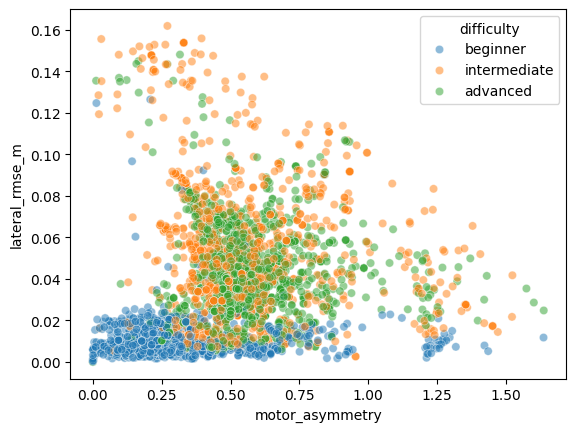

In [138]:
sns.scatterplot(
    data=df,
    x='motor_asymmetry',
    y='lateral_rmse_m',
    hue='difficulty',
    alpha=0.5
)
plt.show()

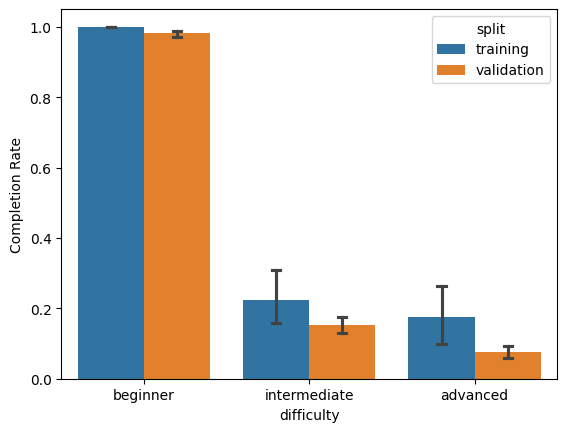

In [139]:
sns.barplot(
    data=df,
    x='difficulty',
    y='completed',
    hue='split',
    errorbar=('ci', 95),
    capsize=0.1
)
plt.ylabel('Completion Rate')
plt.show()

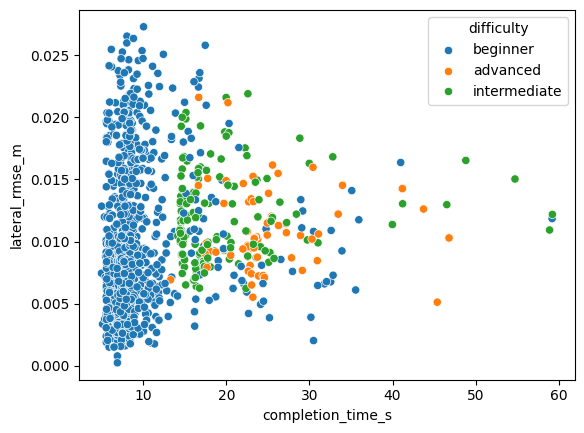

In [140]:
sns.scatterplot(
    data=df[df['completed']],
    x='completion_time_s',
    y='lateral_rmse_m',
    hue='difficulty'
)
plt.show()

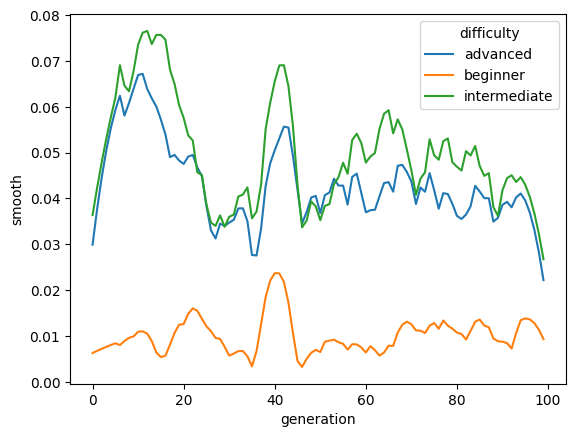

In [141]:
from scipy.signal import savgol_filter

smoothed = df.groupby(['generation', 'difficulty'], as_index=False)['lateral_rmse_m'].mean()
smoothed = smoothed.sort_values('generation')

smoothed['smooth'] = smoothed.groupby('difficulty')['lateral_rmse_m'].transform(
    lambda x: savgol_filter(x, window_length=11, polyorder=2)
)

sns.lineplot(data=smoothed, x='generation', y='smooth', hue='difficulty')
plt.show()

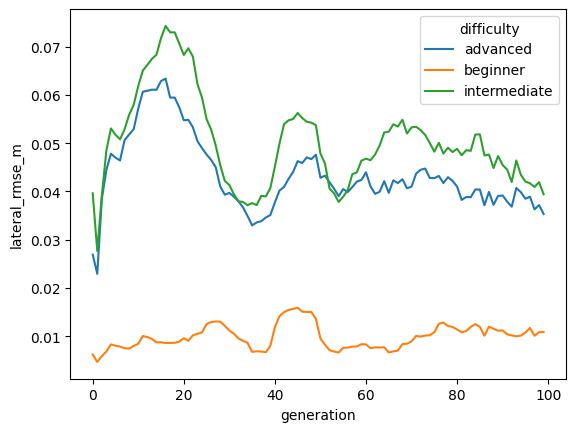

In [142]:
smoothed = df.groupby(['generation', 'difficulty'], as_index=False)['lateral_rmse_m'].mean()

smoothed['lateral_rmse_m'] = smoothed.groupby('difficulty')['lateral_rmse_m'].transform(
    lambda x: x.rolling(window=10, min_periods=1).mean()
)

sns.lineplot(data=smoothed, x='generation', y='lateral_rmse_m', hue='difficulty')
plt.show()

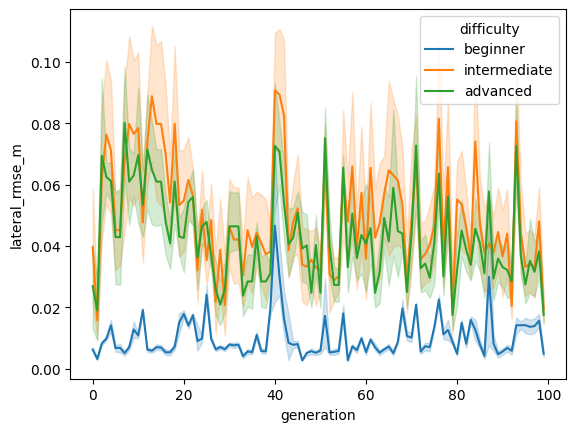

In [143]:
sns.lineplot(data=df, x='generation', y='lateral_rmse_m', hue='difficulty')
plt.show()

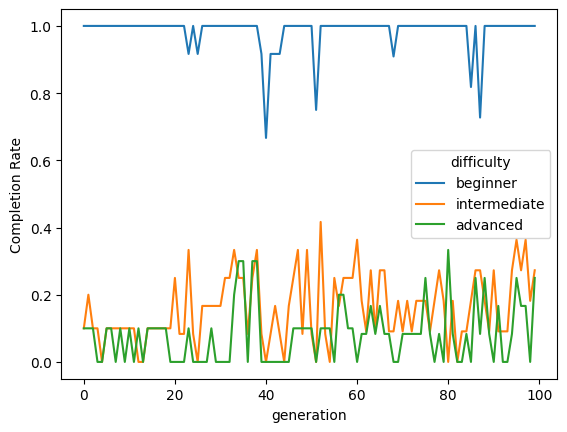

In [144]:
sns.lineplot(data=df, x='generation', y='completed', hue='difficulty', errorbar=None)
plt.ylabel('Completion Rate')
plt.show()

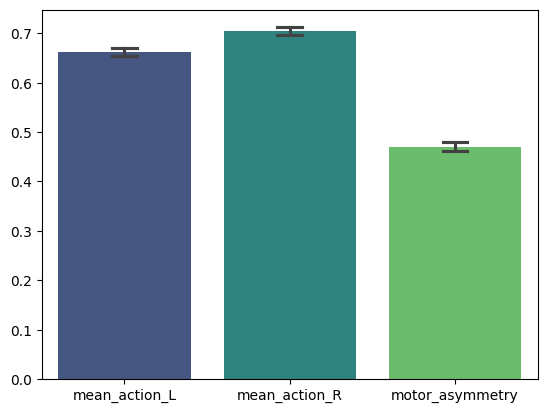

In [145]:
sns.barplot(
    data=df[['mean_action_L', 'mean_action_R', 'motor_asymmetry']],
    errorbar=('ci', 95),
    palette='viridis',
    capsize=0.15,
    )

plt.show()

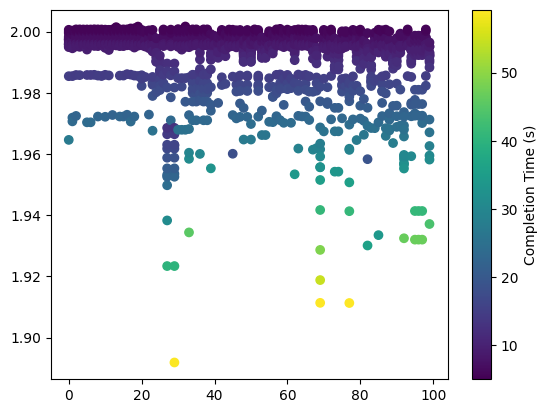

In [146]:
plt.scatter(df['generation'], df['score'], c=df['completion_time_s'], cmap='viridis')
plt.colorbar(label='Completion Time (s)')
plt.show()

In [148]:
df = pd.read_csv(r"runs\28-10-2026\generations.csv")

print(df.columns)
df.head()

Index(['generation', 'condition', 'seed', 'training_mean', 'training_best',
       'validation_completion_rate', 'validation_score', 'physics_steps',
       'episode_slots', 'wall_seconds', 'backend', 'gpu_world_steps_total',
       'gpu_padding_world_steps_total'],
      dtype='object')


,generation,condition,seed,training_mean,training_best,validation_completion_rate,validation_score,physics_steps,episode_slots,wall_seconds,backend,gpu_world_steps_total,gpu_padding_world_steps_total
0,0,curriculum,0,0.435233,1.996191,0.400000,0.487838,5613740,830,316.689077,gpu,7562600,1948860
1,1,curriculum,0,0.669398,1.995993,0.433333,0.552348,6314570,830,395.963428,gpu,16266930,4338620
2,2,curriculum,0,0.852105,1.998090,0.400000,0.509793,6386070,838,403.303320,gpu,24880540,6566160
3,3,curriculum,0,0.817427,1.996455,0.366667,0.482495,5553560,838,420.951226,gpu,32475200,8607260
4,4,curriculum,0,0.787611,1.998219,0.333333,0.456785,5448810,834,347.398970,gpu,39711130,10394380


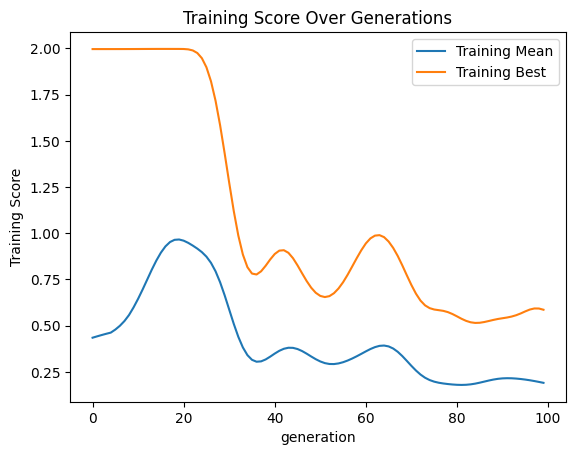

In [160]:
# columns: 	generation	condition	seed	training_mean	training_best	validation_completion_rate	validation_score	physics_steps	episode_slots	wall_seconds	backend	gpu_world_steps_total	gpu_padding_world_steps_total
# apply moving average smoothing to training_mean and training_best columns

df['training_mean'] = df.groupby('condition')['training_mean'].transform(lambda x: x.rolling(window=5, min_periods=1).mean())
df['training_best'] = df.groupby('condition')['training_best'].transform(lambda x: x.rolling(window=5, min_periods=1).mean())

sns.lineplot(data=df, x='generation', y='training_mean', label='Training Mean')
sns.lineplot(data=df, x='generation', y='training_best', label='Training Best')
plt.ylabel('Training Score')
plt.title('Training Score Over Generations')
plt.show()